# エタノール27分子：GROMACS NVTを理解する

**到達目標**：初期条件を再現し、GROMACSの入力と出力を追跡し、短時間RDFを正しく読めるようになる。

300 K・体積固定・0.5 fs・600 steps・拘束なし。100 fsを準備区間、続く200 fsを解析区間とする。これは習熟用の短い計算で、平衡物性は評価しない。

まず第0〜4節を実行する。QM/RESPが未準備でも学べる。第5節にはPySCFでQM/RESP入力を用意する手順がある。初回は第5.2節のセルで単分子QM計算、第6.3節のセルで600-step MDを実行する。完了後の再実行では出典とhashを検証して結果を読む。詳細：[教材README](../README.md)。


## 0. 場所と環境を確認する

Notebookをどこから開いてもrepositoryを探す。`BUILD` は構造生成の出力、`RUN` はMDの出力。実行結果はGit管理しない `runs/` に保存する。

予想：ASE、NumPy、RDKitがあれば前半は実行できる。GROMACSが存在しても、実行可能とは限らない。


In [9]:
from pathlib import Path
import sys, json, importlib.metadata as metadata
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/mdworkbench").is_dir()), None)
if ROOT is None:
    raise RuntimeError("GROMACS-MD-v1内からNotebookを開いてください")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from mdworkbench.ethanol_benchmark import config, build
from mdworkbench.analysis.ethanol_rdf import intermolecular_rdf, production_indices
CONFIG = ROOT / "systems/ethanol_27/system.yaml"
BUILD = ROOT / "runs/ethanol27_initial"
RUN = ROOT / "runs/ethanol27_nvt"
cfg = config(CONFIG)
print("ROOT:", ROOT)
print("Python:", sys.executable)
for name in ["ase", "numpy", "rdkit", "MDAnalysis", "mace-torch"]:
    try: print(name, metadata.version(name))
    except metadata.PackageNotFoundError: print(name, "未導入")
print("仕様で再現対象のversion: ASE 3.29.0 / mace-torch 0.3.16")


ROOT: [REPO_ROOT]
Python: $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/python
ase 3.29.0
numpy 1.26.4
rdkit 2026.3.1
MDAnalysis 2.10.0
mace-torch 0.3.16
仕様で再現対象のversion: ASE 3.29.0 / mace-torch 0.3.16


## 1. 1分子から27分子へ：予想してから作る

ASEのエタノール1分子をCOM中心化し、x軸を(1,1,1)へ向ける。格子の中心 `(index+0.5)×4.6 Å` に配置する。この原点の選択は仕様書にない実装上の約束であり、全体の平行移動に相当する。seed42の独立RNGで各分子にx→y→zの微小回転を加える。

**問い**：9原子×27分子、13.8 Åの立方体なら密度はどのくらいになるか。体積は辺の長さの何乗か。

出力が既存なら読み込む。再作成のために削除せず、BUILDを新しい名前に変える。


In [10]:
if not BUILD.exists():
    build(cfg, BUILD)
report = json.loads((BUILD / "build_report.json").read_text())
data = np.load(BUILD / "initial.npz")
positions = data["positions_A"]
for key in ["atom_count", "molecule_count", "molecular_mass_amu", "volume_A3", "density_g_cm3", "density_warning"]:
    print(key, report[key])
assert positions.shape == (243, 3)
print("ASE原子順:", list(enumerate(report["ase_single_symbols"])))


atom_count 243
molecule_count 27
molecular_mass_amu 46.068999999999996
volume_A3 2628.0720000000015
density_g_cm3 0.7859309429111057
density_warning False
ASE原子順: [(0, 'C'), (1, 'C'), (2, 'O'), (3, 'H'), (4, 'H'), (5, 'H'), (6, 'H'), (7, 'H'), (8, 'H')]


### 箱と分子を描く

描画のためだけに座標を箱へ折り返す。MD入力は元の座標を保つ。境界を跨ぐ共有結合は折り返し表示で長く見えるため、その線を省略する。色はC=黒、O=赤、H=灰。

**グラフの読み方**：3×3×3配置が残っているか。周期箱では右端の原子から左端の原子への距離は、図の直線距離と同じか。


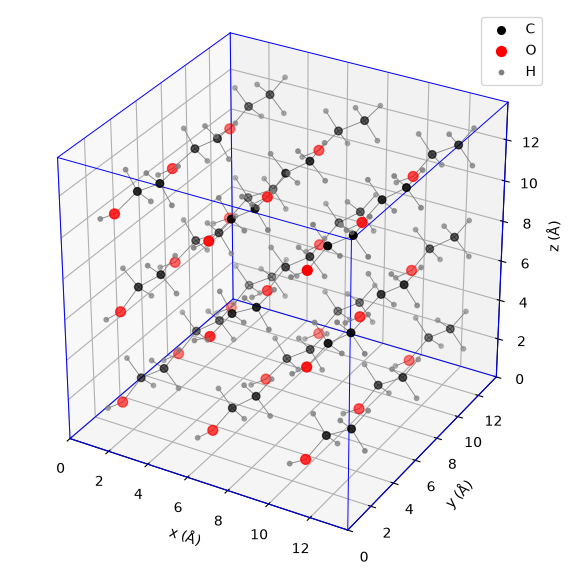

In [11]:
import itertools
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")
wrapped = positions % 13.8
symbols = np.tile(report["ase_single_symbols"], 27)
for symbol, color, size in [("C", "black", 30), ("O", "red", 50), ("H", "gray", 10)]:
    xyz = wrapped[symbols == symbol]
    ax.scatter(*xyz.T, c=color, s=size, label=symbol)
for molecule in range(27):
    for i, j in report["ase_single_bonds"]:
        xyz = wrapped[[9*molecule+i, 9*molecule+j]]
        if np.linalg.norm(xyz[0]-xyz[1]) < 2:
            ax.plot(*xyz.T, color="gray", lw=.6)
for a in itertools.product([0, 13.8], repeat=3):
    for axis in range(3):
        if a[axis] == 0:
            b = list(a); b[axis] = 13.8
            ax.plot(*np.array([a,b]).T, color="blue", lw=.7)
ax.set(xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)", xlim=(0,13.8), ylim=(0,13.8), zlim=(0,13.8))
ax.set_box_aspect((1,1,1)); ax.legend(); plt.show()


## 2. 初期速度：温度とCOMを分けて考える

原子ごとの運動量は `p_i = sqrt(m_i k_B T) ξ_i`（ξは標準正規乱数）。全系のCOM運動を1回引き、運動エネルギー `K=Σ p_i²/(2m_i)` に対して `T=2K/(f k_B)` が300 Kとなるよう全運動量を1回スケールする。

COMの並進3自由度を除いた `f=3×243−3=726` を初期化で採用する。ASEと、MD中のCOM除去を無効にしたGROMACSは729自由度で温度を表示するため、同じ速度でも約298.765 Kとなる。これは初期データとtemperature表示の定義差である。thermostatのref-tは300 K。

**問い**：一回の初期スケールと、MD中のthermostatの役割はどう違うか。各分子のCOM速度もゼロになっているか。


COM速度 (nm/ps): [-1.05322143e-17 -3.24892035e-17 -2.15999649e-17]
T (726 DoF): 299.9999999999999
T (729 DoF): 298.76543209876536
各分子COM速度の最大絶対値 (nm/ps): 0.5464433379604247


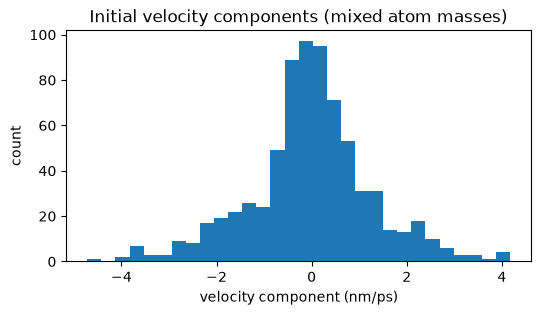

In [12]:
v = data["velocities_nm_ps"]
m = data["masses_amu"]
print("COM速度 (nm/ps):", (m[:,None] * v).sum(axis=0) / m.sum())
print("T (726 DoF):", report["temperature_726_dof_K"])
print("T (729 DoF):", report["temperature_729_dof_K"])
molecular_com_v = (m[:,None] * v).reshape(27,9,3).sum(axis=1) / m.reshape(27,9).sum(axis=1)[:,None]
print("各分子COM速度の最大絶対値 (nm/ps):", np.abs(molecular_com_v).max())
assert np.allclose((m[:,None]*v).sum(axis=0), 0, atol=1e-10)
assert abs(report["temperature_726_dof_K"]-300) < 1e-8
fig, ax = plt.subplots(figsize=(6,3))
ax.hist(v.ravel(), bins=30)
ax.set(xlabel="velocity component (nm/ps)", ylabel="count", title="Initial velocity components (mixed atom masses)")
plt.show()


## 3. RDFを初期配置で練習する

RDF `g(r)` は、中心から距離rに相手原子が現れる頻度を一様配置と比較したもの。今回は各分子からOとOHのHを一つずつ選び、**別分子だけ**数える。同一分子のOH共有結合は除外する。

`g(r) = histogram / [N_frame × 27 × (26/V) × shell_volume]`

`V=13.8³ Å³`、shell_volume=`4π/3 (r_outer³−r_inner³)`。OOも中心→相手の方向付きで数える。minimum imageで `Δr ← Δr−L round(Δr/L)` とする。45bin、r_max=6.762 Å。この節は1枚の初期構造の演習であり、production RDFではない。

**予想**：格子に由来する鋭いピークが現れるか。OH RDFが短距離にピークを持っても、水素結合を角度込みで数えたことになるか。


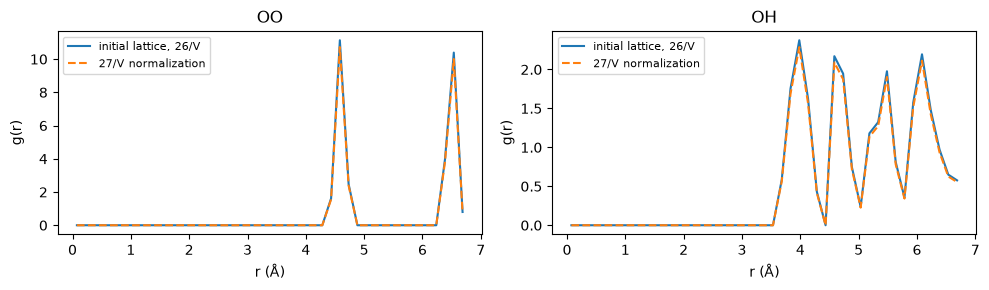

bin幅 (Å): 0.15026666666666666


In [13]:
ids = data["molecule_ids"]
oxygen = np.arange(27)*9 + report["oxygen_ase_index"]
hydroxyl_h = np.arange(27)*9 + report["hydroxyl_h_ase_index"]
initial_rdf = intermolecular_rdf(positions[None,:,:], np.array([[13.8]*3]), ids, oxygen, hydroxyl_h)
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax, name in zip(axes, ["OO", "OH"]):
    ax.plot(initial_rdf["r_A"], initial_rdf[name], label="initial lattice, 26/V")
    ax.plot(initial_rdf["r_A"], initial_rdf[name]*26/27, "--", label="27/V normalization")
    ax.set(xlabel="r (Å)", ylabel="g(r)", title=name)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("bin幅 (Å):", 6.762/45)


## 4. 解析frameを取り違えない

0.5 fs×stepが時刻。5stepごとの保存は2.5 fs間隔。step200を含めず、step205〜600を解析する。80frameは互いに相関するため、80個の独立した標本とは限らない。

**小課題**：step200を含めたら何枚になるか。次のassertを書き換えずに説明する。


In [14]:
saved_steps = np.arange(0, 601, 5)
selected = saved_steps[production_indices(saved_steps)]
print("frame数:", len(selected), "steps:", selected[0], "〜", selected[-1])
print("時刻 (ps):", selected[0]*.0005, "〜", selected[-1]*.0005)
assert len(selected)==80 and 200 not in selected


frame数: 80 steps: 205 〜 600
時刻 (ps): 0.10250000000000001 〜 0.3


## 5. RESPとGAFF：MDの前に入力を読む

ここからは、このMacで無料の **PySCF → AmberTools RESP → GAFF2 → ACPYPE** を使う。第0〜4節を実行済みで、`BUILD / "ethanol_single.sdf"` が存在することを確認する。

RESPはQMの静電ポテンシャルを原子電荷で近似する方法。GAFF2は結合・角度・ねじれ・LJなどを与える力場。SMILESやSDFだけではRESP電荷は決まらない。

このレッスンでは、**孤立エタノール1配座を気相RHF/6-31G*で構造最適化**してから静電ポテンシャルを計算する。電荷を求めるための単分子だけを最適化し、第1節の27分子の座標と速度は保持する。初回のみ計算し、再実行時は入力・出力hashを検証して結果を読む。エラーで途中停止した場合や条件を変える場合は、新しい`QM`/`PARAMS`/`RUN`名を使う。

**今回の採用条件**：独自のFibonacci表面格子、vdW半径 H=1.20/C=1.70/O=1.52 Å、1.4/1.6/1.8/2.0倍の4層、約1点/Å²。他原子の同じ層の球内にある点は除く。GaussianのMK格子と同一ではなく、会社PCのGaussian結果と数値が一致する保証はない。単配座の操作教材であり、配座平均・振動解析による極小確認・液体物性の検証は含まない。

処理本体は`src/mdworkbench/parameterization/pyscf_ethanol.py`。出典：[PySCF構造最適化](https://pyscf.org/user/geomopt.html)、[PySCF静電ポテンシャルの実装](https://pyscf.org/_modules/pyscf/tools/cubegen.html)、[Amber ESP書式](https://github.com/Amber-MD/AmberClassic/blob/main/src/antechamber/espgen.c)。


### 5.1 ライブラリと保存先を確認する

カーネルは **Python (GROMACS MD Workbench)**（`gmx-md`）。このPCにはPySCFとgeomeTRICを導入済み。別のPCで不足する場合は、新しいセルで `qm_requirements = str(ROOT / "env/requirements-qm.txt")`、続いて `%pip install --prefer-binary -r "$qm_requirements"` を実行し、カーネルを再起動して第0〜4節を再実行する。

`QM`は量子化学・RESP、`PARAMS`は力場生成、`RUN`はMDの出力。元の`systems/ethanol_27/system.yaml`は未決定項目を残したテンプレートとして保持し、今回の値は`QM`内の設定に保存する。


In [17]:
import pyscf, geometric, shutil
from mdworkbench.parameterization import pyscf_ethanol as lesson
from mdworkbench import ethanol_benchmark as bench

print("Python:", sys.executable)
print("PySCF:", pyscf.__version__, "geomeTRIC:", geometric.__version__)
for name in ["resp", "antechamber", "parmchk2", "tleap", "acpype"]:
    print(name, shutil.which(name))
    if shutil.which(name) is None:
        raise RuntimeError(f"{name}が見つかりません。gmx-mdカーネルを選択してください")
QM = ROOT / "runs/ethanol27_pyscf"
PARAMS = ROOT / "runs/ethanol27_pyscf_parameters"
RUN = ROOT / "runs/ethanol27_pyscf_nvt"
sdf = BUILD / "ethanol_single.sdf"
assert sdf.is_file(), "先に第1節を実行してください"
print("単分子SDF:", sdf)


Python: $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/python
PySCF: 2.14.0 geomeTRIC: 1.1.1
resp $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/resp
antechamber $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/antechamber
parmchk2 $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/parmchk2
tleap $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/tleap
acpype $HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/bin/acpype
単分子SDF: [REPO_ROOT]/runs/ethanol27_initial/ethanol_single.sdf


### 5.2 単分子の構造を最適化する

電子の波動関数を原子核の位置に対して解き、力に沿って原子核を動かしていく。全電荷0、スピン一重項（PySCFでは`spin=0`）。電子状態のSCF収束と、構造最適化の収束は別々に確認する。

**成功の目印**：2種類の`converged`が`True`で、9原子の結合関係が変わっていないこと。エネルギーの単位はHartree。これは孤立分子の電子エネルギーで、第7節の古典力場のPotentialとは直接比較しない。詳細は`QM / "pyscf.log"`。


In [18]:
qm_report = lesson.optimize(sdf, QM)
print("geometry_converged:", qm_report["geometry_converged"])
print("scf_converged:", qm_report["scf_converged"])
print("RHF/6-31G* energy (Hartree):", qm_report["energy_hartree"])
print("最適化後の構造:", QM / "optimized.xyz")
for i, symbol in enumerate(qm_report["symbols"]):
    print(i, symbol)


geometry_converged: True
scf_converged: True
RHF/6-31G* energy (Hartree): -154.07436585223127
最適化後の構造: [REPO_ROOT]/runs/ethanol27_pyscf/optimized.xyz
0 C
1 C
2 O
3 H
4 H
5 H
6 H
7 H
8 H


### 5.3 分子の外側で静電ポテンシャルを計算する

正の試験電荷が分子の周囲で感じるポテンシャルは、原子核の正の寄与から電子の負の寄与を引いたもの：`V(r) = Σ Z_A/|r−R_A| − ∫ρ(r′)/|r−r′| dr′`（原子単位系）。

ここでは表面格子の座標とVを計算し、AmberのRESPが読める`qm.esp`へ保存する。**座標はNotebook/npzではÅ、RESP入力ではbohr**、VはHartree/e。図は静電ポテンシャルの正負を表す。青は負、赤は正、黒点は原子核。分子全体の電荷が0でも、分子の近くではVは0にならない。


ESP格子点数: 625


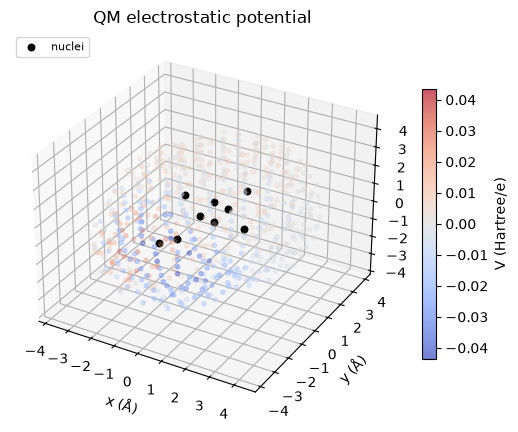

In [19]:
esp_report = lesson.make_esp(QM)
print("ESP格子点数:", esp_report["point_count"])
grid_data = np.load(QM / "esp_grid.npz")
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
grid = grid_data["grid_A"]
limit = np.max(np.abs(grid_data["esp_au"]))
points = ax.scatter(*grid.T, c=grid_data["esp_au"], cmap="coolwarm", s=9,
                    vmin=-limit, vmax=limit, alpha=.7)
ax.scatter(*grid_data["coords_A"].T, c="black", s=22, label="nuclei", depthshade=False)
ax.legend(loc="upper left", fontsize=8)
ax.set(xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)", title="QM electrostatic potential")
fig.colorbar(points, ax=ax, shrink=.7, label="V (Hartree/e)")
plt.show()


### 5.4 2段階のRESPで9個の原子電荷を求める

点電荷モデルの`V_fit(r) = Σ q_A/|r−R_A|`をQMのVに近づける。RESPは単なる最小二乗に弱い抑制項を加え、過大な電荷を抑える。

- stage 1：全電荷0、全原子をfit、重原子の抑制強度`qwt=0.0005`、Hの抑制なし（`ihfree=1`）。
- stage 2：`qwt=0.001`。OとOHのHはstage 1の値に固定。CH3の3個のH、CH2の2個のHをそれぞれ等価にし、CとC結合Hを再fitする。

これはこの教材で明示した単配座の2段階レシピ。`resp1.in`/`resp2.in`が実際の拘束、`resp1.out`/`resp2.out`が収束記録。電荷ファイルの丸めにより総和に約10⁻⁶ e程度の差が残ることがある。RESP原本を保存し、総和の許容誤差10⁻⁴ e以内を確認する。AmberToolsの変換時に中性化のための丸め補正が入る場合は、topologyとの差（許容誤差10⁻⁵ e）も第5.6節で表示する。

**図の読み方**：左は原子ごとの電荷（単位e）。右は同じ点でのQMと点電荷モデルのV。対角線に近いほどESPの再現がよいが、点電荷だけでは電子分布を完全には表現できない。RMS誤差が0でなくても直ちに計算失敗ではない。


 0 C  -0.083266 e
 1 C  +0.352347 e
 2 O  -0.680391 e
 3 H  +0.415256 e
 4 H  -0.042525 e
 5 H  -0.042525 e
 6 H  +0.027035 e
 7 H  +0.027035 e
 8 H  +0.027035 e
総和 (e): 1.0000000000599807e-06
ESP RMS誤差 (Hartree/e): 0.0017533816622135024


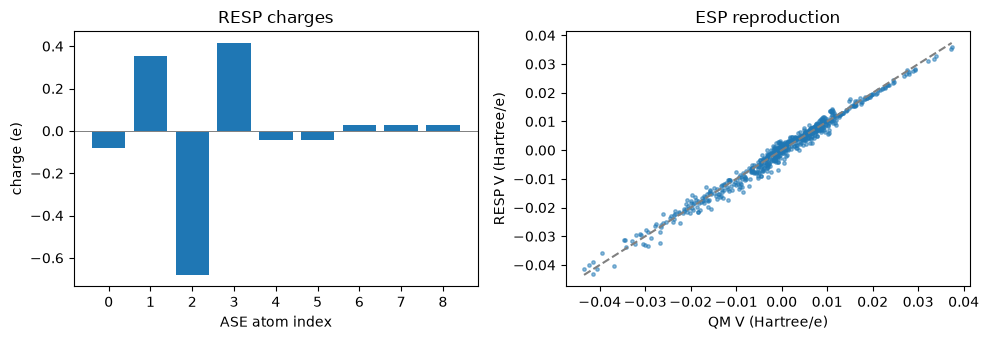

In [20]:
resp_report = lesson.fit_resp(QM)
charges = np.asarray(resp_report["charges"])
for i, (symbol, charge) in enumerate(zip(qm_report["symbols"], charges)):
    print(f"{i:2d} {symbol:2s} {charge:+.6f} e")
print("総和 (e):", resp_report["sum_charge"])
print("ESP RMS誤差 (Hartree/e):", resp_report["esp_rmse_au"])
assert abs(charges.sum()) < 1e-4
fit_data = np.load(QM / "esp_fit.npz")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(np.arange(9), charges)
axes[0].set(xticks=np.arange(9), xlabel="ASE atom index", ylabel="charge (e)", title="RESP charges")
axes[0].axhline(0, color="gray", lw=.7)
x, y = fit_data["qm_esp_au"], fit_data["fitted_esp_au"]
axes[1].scatter(x, y, s=6, alpha=.5)
lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
axes[1].plot([lo, hi], [lo, hi], color="gray", ls="--")
axes[1].set(xlabel="QM V (Hartree/e)", ylabel="RESP V (Hartree/e)", title="ESP reproduction")
plt.tight_layout(); plt.show()


### 5.5 GAFF2の力場を作り、GROMACS形式に変換する

RESP電荷と最適化後SDFから、`antechamber → parmchk2 → tleap → ACPYPE`を実行する。電荷は読み込み専用で、AM1-BCCに置き換えない。`frcmod`に追加項目がなくても、GAFF2の標準ファイルに必要な項目がある場合は正常。

ACPYPEの出力directory名は入力により異なる。実際に生成された`*_GMX.top`を次のセルで探す。既存の力場出力はmetadataのhashを検証して再利用する。不完全な出力を上書きして再試行しない。


In [21]:
PARAM_CONFIG = lesson.parameter_config(CONFIG, QM)
lesson.parameterize(PARAM_CONFIG, PARAMS)
print("力場出力:", PARAMS)
print((PARAMS / "parameters.frcmod").read_text())


力場出力: [REPO_ROOT]/runs/ethanol27_pyscf_parameters
Remark line goes here
MASS

BOND

ANGLE

DIHE

IMPROPER

NONBON






### 5.6 原子対応・1–4相互作用を点検する

`ase_atom_order[i]`は「GROMACS topologyの原子iは、ASEの何番の原子か」。元素だけではH同士を区別できないので、変換前後の**座標と結合関係**を照合してmappingを決め、電荷も一致するか確認する。

確認するもの：9原子/8結合、bond/angle/dihedralのパラメータ、LJ、組合せ規則2、明示的な1–4 pair、1–4 LJ係数0.5、Coulomb係数1/1.2。1–2/1–3の除外を含む最終解釈は、第6節で`grompp`が出す`processed.top`も点検する。自動検査は入力整合性の確認であり、液体物性の妥当性を証明するものではない。


In [22]:
topology_review = lesson.review_topology(QM, PARAMS)
print("入力整合性チェック:", topology_review["checks_passed"])
print("topology → ASE:", topology_review["ase_atom_order"])
print("1–4 / combination rules:", topology_review["defaults"])
print("nrexcl:", topology_review["nrexcl"])
print("電荷の丸め補正差 (e):", topology_review["charge_rounding_delta_e"])
print("topologyの電荷総和 (e):", topology_review["topology_charge_sum"])
print("結合/角度/ねじれ/1–4 pair数:", *(topology_review[k] for k in ["bonds", "angles", "dihedrals", "pairs_14"]))
for atom in topology_review["atoms"]:
    print(f"top={atom['topology_index']} ASE={atom['ase_index']} {atom['name']:3s} "
          f"type={atom['type']:3s} q={atom['charge']:+.6f} e "
          f"sigma={atom['sigma_A']:.4f} Å epsilon={atom['epsilon_kcal_mol']:.4f} kcal/mol")
SINGLE_TOP = Path(topology_review["single_top"])


入力整合性チェック: True
topology → ASE: [0, 1, 2, 3, 4, 5, 6, 7, 8]
1–4 / combination rules: {'nbfunc': 1, 'comb_rule': 2, 'gen_pairs': 'yes', 'fudgeLJ': 0.5, 'fudgeQQ': 0.8333333333}
nrexcl: 3
電荷の丸め補正差 (e): [0.0, 0.0, -1.0000000000287557e-06, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
topologyの電荷総和 (e): 3.469446951953614e-17
結合/角度/ねじれ/1–4 pair数: 8 13 12 12
top=0 ASE=0 C1  type=c3  q=-0.083266 e sigma=3.3977 Å epsilon=0.1078 kcal/mol
top=1 ASE=1 C2  type=c3  q=+0.352347 e sigma=3.3977 Å epsilon=0.1078 kcal/mol
top=2 ASE=2 O1  type=oh  q=-0.680392 e sigma=3.2429 Å epsilon=0.0930 kcal/mol
top=3 ASE=3 H1  type=ho  q=+0.415256 e sigma=0.5379 Å epsilon=0.0047 kcal/mol
top=4 ASE=4 H2  type=h1  q=-0.042525 e sigma=2.4220 Å epsilon=0.0208 kcal/mol
top=5 ASE=5 H3  type=h1  q=-0.042525 e sigma=2.4220 Å epsilon=0.0208 kcal/mol
top=6 ASE=6 H4  type=hc  q=+0.027035 e sigma=2.6002 Å epsilon=0.0208 kcal/mol
top=7 ASE=7 H5  type=hc  q=+0.027035 e sigma=2.6002 Å epsilon=0.0208 kcal/mol
top=8 ASE=8 H6  type=hc  q=+0.027035 

### 5.7 今回の短いMDに使う条件を保存する

1.38 nm箱の半分は0.69 nm。今回の操作学習では`rlist=rcoulomb=rvdw=0.60 nm`、静電相互作用はPME、LJはCut-offと平均場分散補正`EnerPres`を採用する。この小cutoffは収束した物性評価向けの推奨条件ではない。

ゼロステップでの最大forceの停止閾値は10000 kJ/mol/nm。1 uの原子に0.5 fsで約0.0125 Åの半ステップ加速度変位を与える大きさを目安にした操作用screenで、安定性の保証ではない。異常なら停止し、閾値を自動で引き上げない。

ここまでの整合性検査に合格したら、採用理由・mapping・RESP出典を`QM/system.yaml`に保存する。元のテンプレートの`null`を仮の値で埋める操作はしない。


In [23]:
MD_CONFIG = lesson.md_config(QM, topology_review)
cfg = bench.config(MD_CONFIG)
bench.scientific_inputs(cfg, MD_CONFIG.parent)
for section in ["force_field", "resp", "nonbonded", "review"]:
    print(section, json.dumps(cfg[section], ensure_ascii=False, indent=2))
print("MD用config:", MD_CONFIG)
print("次は第6節へ。")


force_field {
  "family": "gaff2",
  "charge_model": "resp"
}
resp {
  "qm_backend": "PySCF 2.14.0",
  "method": "RHF",
  "basis": "6-31G*",
  "geometry_file": "optimized.xyz",
  "esp_conditions": {
    "qm_report": "a65f263af0585436a79c7f520eb70f565e215f98d167b7685a3b2a8ab3625d02",
    "radii_A": {
      "H": 1.2,
      "C": 1.7,
      "O": 1.52
    },
    "scales": [
      1.4,
      1.6,
      1.8,
      2.0
    ],
    "density_per_A2": 1.0,
    "algorithm": "Fibonacci exposed shells v1"
  },
  "fitting_conditions": {
    "esp_report": "746bc67dc34654e5f403a0397337c5a7a6aa9b47475810b4bf1fd45a2cfd64cc",
    "stages": [
      0.0005,
      0.001
    ],
    "ihfree": 1,
    "hydrogen_groups": [
      [
        6,
        7,
        8
      ],
      [
        4,
        5
      ]
    ],
    "stage2_fixed": "O and hydroxyl H",
    "recipe_version": 1
  },
  "source_kind": "charges",
  "source_file": "resp.charges",
  "atom_order_confirmed": true,
  "fit_inputs": [
    "resp1.in",
    "re

## 6. GROMACSの入力を実行へつなぐ

第5節を順に実行した後、以下のセルを順番に実行する。`prepare → preflight → run → analyze`をNotebookから呼び出す。初回は実際の600ステップMDが走る。完了済みの段階はhashと実行記録を確認して読み込む。

| ファイル | 何を表すか | 点検する内容 |
|---|---|---|
| initial.gro | 座標nm、速度nm/ps、box | 原子順と速度が残っているか |
| topology/system.top + includes | 相互作用 | [molecules]が27、電荷と1–4規則 |
| nvt.mdp | 積分・温度制御・保存 | md-vv、constraints none、gen-vel no |
| nvt.tpr | gromppで統合したrun input | warningなし、自由度・質量の解釈 |
| nvt.log / EDR | 計算ログ・エネルギー | step600、温度・forceの異常 |
| nvt.xtc | 軌跡 | box固定、時間とframe数 |
| metadata.json | 出典とhash | version・command・入力の追跡 |

preflightは元の座標で0-stepのenergy/forceを評価する。問題があればEMをせず停止。NVTは元の初期速度から600stepを連続実行し、equilibration/productionの分割は解析時だけ行う。

**問い**：`gen-vel=yes` にすると何が比較不能になるか。`constraints=h-bonds` にすると、0.5 fs以外に何が変わるか。


### 6.1 prepare：27分子の入力を作る

元の座標・速度をtopology順へ並べ替えてGROに保存し、topologyを27分子に展開する。既存入力に変更を検出したら停止する。`force_field_report.json`と`topology/`を照合する。


In [24]:
if not RUN.exists():
    bench.prepare(cfg, MD_CONFIG, BUILD, SINGLE_TOP, RUN)
else:
    bench.verify_snapshot(RUN)
    if bench.config(RUN / "system.yaml") != cfg:
        raise ValueError("既存MDの条件が異なります。新しいRUN名を使ってください")
print((RUN / "nvt.mdp").read_text())
print("NHC: tdamp=50 fs → tau_t≈2π×0.05=0.314159 ps, chain length=3")


integrator = md-vv
 dt = 0.0005
 nsteps = 600
 constraints = none
 tcoupl = nose-hoover
 tc-grps = System
 tau-t = 0.3141592654
 ref-t = 300
 nh-chain-length = 3
 nsttcouple = 1
 pcoupl = no
 gen-vel = no
 continuation = no
 comm-mode = none
 nstcomm = 0
 pbc = xyz
 cutoff-scheme = Verlet
 nstlist = 1
 verlet-buffer-tolerance = -1
 rlist = 0.6
 coulombtype = PME
 rcoulomb = 0.6
 vdwtype = Cut-off
 rvdw = 0.6
 DispCorr = EnerPres
 nstxout = 0
 nstvout = 0
 nstfout = 0
 nstxout-compressed = 5
 compressed-x-precision = 100000
 nstcalcenergy = 1
 nstenergy = 5
 nstlog = 5

NHC: tdamp=50 fs → tau_t≈2π×0.05=0.314159 ps, chain length=3


### 6.2 preflight：ゼロステップで力とエネルギーを確認する

`grompp`は座標・力場・MD条件をTPRにまとめる。warningを無視する`-maxwarn`は使わない。次に元の座標で0-step評価し、有限値・最大force・分子間の最短距離を検査する。`safe=True`になった場合だけ次へ進む。失敗時にEMや閾値変更で自動的に通さない。


In [25]:
preflight_report_path = RUN / "preflight_report.json"
if not preflight_report_path.exists():
    bench.preflight(RUN)
preflight_report = json.loads(preflight_report_path.read_text())
bench.verify_snapshot(RUN)
from mdworkbench.provenance.metadata import hash_file
for filename, digest in preflight_report["output_hashes"].items():
    assert hash_file(RUN / filename) == digest, f"preflight出力変更: {filename}"
print(json.dumps(preflight_report, ensure_ascii=False, indent=2))
assert preflight_report["safe"], "初期条件の問題を調べてください。MDは開始しません"


{
  "safe": true,
  "potential_kJ_mol": [
    -1228.199707
  ],
  "max_force_kJ_mol_nm": 2008.67822265625,
  "closest_intermolecular_A": 1.7446976900100708,
  "output_hashes": {
    "preflight.tpr": "3bb107b5ca453f0832c687428a9028ac88d7932536da128336536ed12e45a753",
    "preflight.trr": "570844dc8ce4116cec01fce92c86a1c9af1236f5ec97ac190af8deb8dd32dd8f",
    "preflight.edr": "96fd51fb1f704efb92ed277bad2cc89dbea660073c8313a24e5fc1290f8ddcf4",
    "processed.top": "e3693ad9890022af5f78e09ebb0bc5b81b2eaa0880f1c3af7fb4c513aef54345"
  }
}


### 6.3 600ステップのNVTを実行し、RDFを解析する

元の初期座標・速度から300 fsの連続MDを実行する。0-step評価のcheckpointからは開始しない。完了後にstep205〜600の80frameだけをRDFに使う。温度・Potential・RDFは第7〜8節で描く。

**確認済みの例外（2026-10-21にユーザーが採用）**：GROMACS 2025.4は`comm-mode=none`に対して重心運動の数値誤差に関する警告を出す。まず通常の`grompp`を実行し、停止原因がその既知の警告1件だけと完全一致した場合に限り、`-maxwarn 1`で再実行する。追加の警告・topologyの警告・別のエラーがある場合は停止する。再実行後も警告内容を再照合し、両ログと許可理由をmetadataに残す。全系COMをMD中に繰り返し除去しない条件を保つための限定例外で、一般的な警告無視の許可ではない。


In [26]:
run_metadata = json.loads((RUN / "metadata.json").read_text())
bench.verify_snapshot(RUN)
if run_metadata.get("status") != "completed":
    bench.run_nvt(RUN, allow_com_warning=True)
else:
    for filename, digest in run_metadata["output_hashes"].items():
        assert hash_file(RUN / filename) == digest, f"MD出力変更: {filename}"
bench.analyze(RUN)
print("600ステップ完了。次は第7〜8節で温度・Potential・RDFを確認。")


$HOME/.local/share/mdworkbench/GROMACS-MD-v1/micromamba/envs/gmx-md/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


600ステップ完了。次は第7〜8節で温度・Potential・RDFを確認。


## 7. 温度・Potentialを読む（実MD出力がある場合）

温度は常に300 Kに固定されるわけではない。NHCは熱浴とのエネルギー交換で温度分布を制御する。100 fsは平衡化を保証する長さではない。PotentialはkJ/mol（シミュレーションboxの系）で表示する。異なるpotential間ではエネルギー原点が異なり、絶対値の一致を期待しない。

**見る順序**：時間の単位→100 fs境界→不連続や発散→変動の時間尺度。平均が300 Kに近いだけで、平衡を断定しない。


GROMACSのseries labels:
@ legend on
@ legend box on
@ legend loctype view
@ legend 0.78, 0.8
@ legend length 2
@ s0 legend "Potential"
@ s1 legend "Temperature"



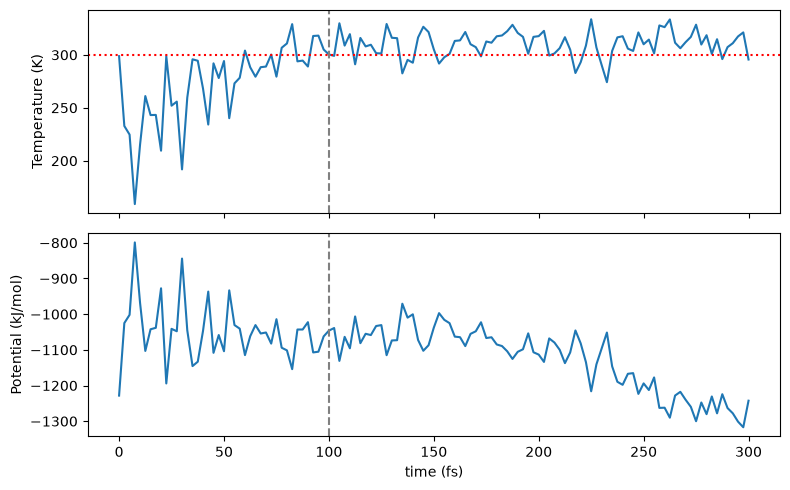

In [27]:
trace = RUN / "thermodynamics.xvg"
if trace.exists():
    from mdworkbench.ethanol_benchmark import read_thermodynamics
    time_ps, temperature_K, potential_kJ_mol = read_thermodynamics(trace)
    print("GROMACSのseries labels:")
    print("".join(line for line in trace.read_text().splitlines(True) if 'legend' in line))
    fig, axes = plt.subplots(2,1,figsize=(8,5),sharex=True)
    for ax, series, label in [(axes[0],temperature_K,"Temperature (K)"),(axes[1],potential_kJ_mol,"Potential (kJ/mol)")]:
        ax.plot(time_ps*1000, series); ax.axvline(100,color="gray",ls="--")
        ax.set_ylabel(label)
    axes[0].axhline(300,color="red",ls=":")
    axes[1].set_xlabel("time (fs)"); plt.tight_layout(); plt.show()
else:
    print("実MDは未実行：thermodynamics.xvg が生成された後に再実行してください。")


## 8. Production RDFと将来のMACE比較

80frameの平均でも200 fsしかない。初期配置の記憶が残る可能性が高い。ピークの位置と高さを初期RDFと比較し、変化の意味と不確かさを分けて説明する。

MACE referenceが将来できたら、READMEのadapter経由で同じ関数へ渡す。現在はreferenceがないため曲線を生成しない。potentialが違うのでtrajectory/RDFの一致は目的ではない。


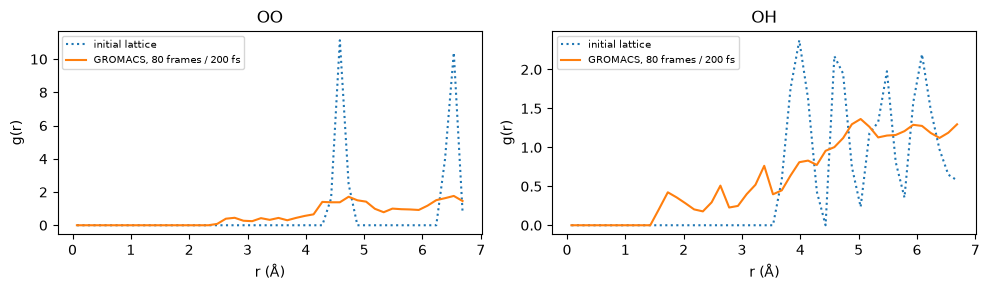

In [28]:
rdf_path = RUN / "rdf_gromacs.npz"
if rdf_path.exists():
    rdf_data = np.load(rdf_path)
    assert np.array_equal(rdf_data["steps"], np.arange(205,601,5))
    fig, axes = plt.subplots(1,2,figsize=(10,3))
    for ax, name in zip(axes,["OO","OH"]):
        ax.plot(initial_rdf["r_A"],initial_rdf[name],":",label="initial lattice")
        ax.plot(rdf_data["r_A"],rdf_data[name],label="GROMACS, 80 frames / 200 fs")
        if (RUN/"rdf_mace.npz").exists():
            reference=np.load(RUN/"rdf_mace.npz")
            ax.plot(reference["r_A"],reference[name],label="MACE reference")
        ax.set(xlabel="r (Å)",ylabel="g(r)",title=name); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("production RDF未生成：MD後に analyze commandを実行してください。")


## 9. 自分の言葉で説明する

1. 初期条件が同じでもpotentialが違うと加速度・trajectoryはなぜ変わるか。
2. thermostatの質量を対応させても積分方法・自由度・内部状態の差は何か。
3. 拘束なしで0.5 fsを使う理由は何か。
4. 200 fs/80frameで収束RDFを主張できない理由は何か。
5. OOとOH RDFの違いと、角度を含む水素結合判定の違いは何か。
6. 初期格子の影響はどの曲線にどう見えたか。
7. 26/Vと27/VでRDFが26/27倍になる理由を説明する。
8. 「条件を揃える」で揃えたものと、未検証・異なるものを列挙する。

### 観察メモ（ここへ記入）

- 実行済みの範囲：
- 確認したversionとhash：
- 予想と実際の違い：
- 未準備の科学入力：
- 結果から言えること：
- まだ言えないこと：

出典：[GROMACS MDP](https://manual.gromacs.org/documentation/current/user-guide/mdp-options.html)、[GROMACS thermostat](https://manual.gromacs.org/2022/reference-manual/algorithms/molecular-dynamics.html)、[ASE NHC implementation](https://docs.ase-lib.org/_modules/ase/md/nose_hoover_chain.html)。採用値と温度定義の差はREADMEを参照。
